# Step 3 — ICP recovery: three-panel validation figure
Place this notebook in `assignments/assignment3/notebooks/` beside your assignment notebook, then **Run All**. It uses your existing `src/student/icp.py` and the supplied femur mesh; no server or token is needed. Requires NumPy and Matplotlib plus your assignment dependencies.

Reproduces `test_icp_recovers_transform_from_surface_samples`: 150 noiseless surface points (seed 0), known transform (seed 3), and a left perturbation of 0.15 rad about z plus (5,-5,3) mm. A and B share identical axes. C compares errors against the known original surface points, not closest-point residuals. The figure and summary report the actual outcome, including failures.

AI assistance: ChatGPT generated this notebook from the prompt “can you generate an ipnyb that creates the three figure panel”. Retain this disclosure in your assignment report.

In [2]:
from pathlib import Path
import sys
import json
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Optional: set this to the full path of assignments/assignment3.
ASSIGNMENT_DIR = None
if ASSIGNMENT_DIR is None:
    candidates = [Path.cwd(), *Path.cwd().parents]
    candidates += [p / 'assignments' / 'assignment3' for p in list(candidates)]
    assignment = next((p for p in candidates
                       if (p/'src/student/icp.py').is_file()
                       and (p/'data/ProximalFemurMeshFile.sur').is_file()), None)
    if assignment is None:
        raise FileNotFoundError('Put this notebook in assignment3/notebooks, or set ASSIGNMENT_DIR above.')
else:
    assignment = Path(ASSIGNMENT_DIR).expanduser().resolve()
# Match the course notebook import structure.
sys.path.insert(0, str(assignment.parents[1]))
sys.path.insert(0, str(assignment))
from src import vct3, Rot, Frame, load_sur
from src.student import icp
mesh = load_sur(assignment/'data/ProximalFemurMeshFile.sur')
OUTPUT = Path.cwd()/'step3_icp_figures'
OUTPUT.mkdir(exist_ok=True)
print('Using ICP:', icp.__file__)
print('Mesh:', mesh.n_vertices, 'vertices;', mesh.n_triangles, 'triangles')

Using ICP: /Users/adithichitiprolu/Desktop/CIS_I_assignments/assignments/assignment3/src/student/icp.py
Mesh: 1568 vertices; 3135 triangles


In [3]:
def apply_frame(F, points):
    """Transform Nx3 row-stored points using a course Frame; returns Nx3."""
    return points @ F.R.matrix.T + F.p.vec.ravel()

# Exactly the surface_points fixture from the unit test.
rng = np.random.default_rng(0)
tri = rng.choice(mesh.n_triangles, size=150, p=mesh.areas/mesh.areas.sum())
r1, r2 = rng.uniform(size=(2,150))
flip = r1+r2 > 1
r1[flip], r2[flip] = 1-r1[flip], 1-r2[flip]
bary = np.stack([1-r1-r2, r1, r2], axis=1)
surface_points = np.einsum('kj,kjd->kd', bary, mesh.tri_vertices[tri])

rng = np.random.default_rng(3)
axis = rng.normal(size=3)
axis /= np.linalg.norm(axis)
F_true = Frame(Rot(vct3(axis), angle=rng.uniform(-0.5,0.5)),
               vct3(rng.uniform(-20.0,20.0,3)))
d = apply_frame(F_true.inv(), surface_points)
F_init = Frame(Rot(vct3(0,0,1), angle=0.15), vct3(5,-5,3))*F_true
initial_points = apply_frame(F_init, d)

# Uses your function, with the same defaults as the unit test.
result = icp.icp(d, mesh, F_init, max_iter=100)
recovered_points = apply_frame(result.F_reg, d)
errors = np.linalg.norm(recovered_points-surface_points, axis=1)
initial_errors = np.linalg.norm(initial_points-surface_points, axis=1)
THRESHOLD_MM = 0.05
passed = bool(result.converged and errors.max() < THRESHOLD_MM)
summary = dict(passed=passed, converged=bool(result.converged),
               iterations=int(result.n_iter), n_samples=len(d),
               initial_max_mm=float(initial_errors.max()),
               final_max_mm=float(errors.max()),
               final_rms_mm=float(np.sqrt(np.mean(errors**2))),
               threshold_mm=THRESHOLD_MM)
print(json.dumps(summary, indent=2))

{
  "passed": true,
  "converged": true,
  "iterations": 88,
  "n_samples": 150,
  "initial_max_mm": 13.931958509059665,
  "final_max_mm": 0.009461153182767962,
  "final_rms_mm": 0.004587860912855904,
  "threshold_mm": 0.05
}


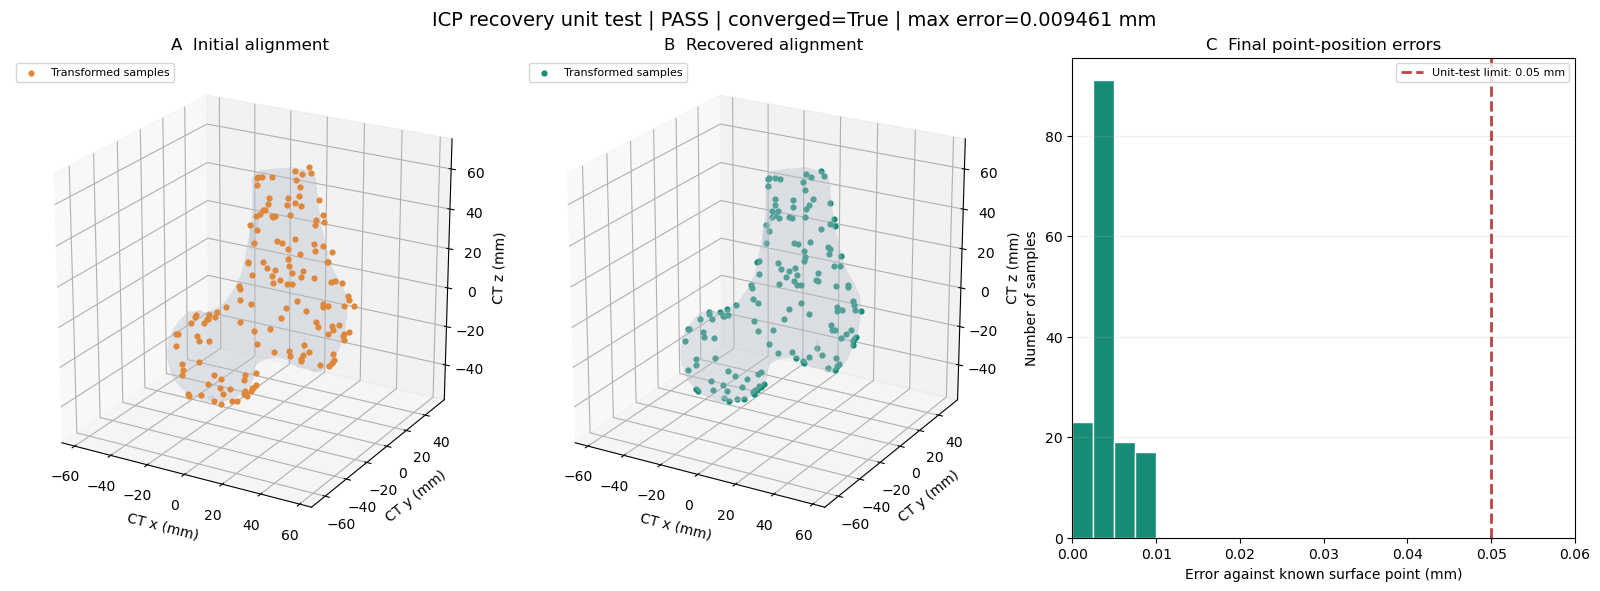

Saved PNG, PDF, errors CSV and summary to: /Users/adithichitiprolu/Desktop/CIS_I_assignments/assignments/assignment3/step3_icp_figures
Caption: ICP recovery from 150 noiseless synthetic femur surface samples. An initially perturbed registration was refined using ICP. The maximum final error was 0.00946115 mm; the test requires convergence and a maximum error below 0.05 mm. Outcome: PASS.


In [4]:
fig = plt.figure(figsize=(16,5.8), layout='constrained')
a = fig.add_subplot(131, projection='3d')
b = fig.add_subplot(132, projection='3d')
c = fig.add_subplot(133)
all_points = np.vstack([mesh.vertices, initial_points, recovered_points])
center = (all_points.min(axis=0)+all_points.max(axis=0))/2
radius = np.ptp(all_points,axis=0).max()*0.55

for ax, points, color, title in [
    (a,initial_points,'#df873b','A  Initial alignment'),
    (b,recovered_points,'#168c76','B  Recovered alignment')]:
    ax.add_collection3d(Poly3DCollection(mesh.tri_vertices,
        facecolor='#b8c2ce', edgecolor='none', alpha=0.22))
    ax.scatter(*points.T, s=12, color=color, depthshade=False, label='Transformed samples')
    ax.set(xlim=(center[0]-radius,center[0]+radius),
           ylim=(center[1]-radius,center[1]+radius),
           zlim=(center[2]-radius,center[2]+radius),
           xlabel='CT x (mm)', ylabel='CT y (mm)', zlabel='CT z (mm)', title=title)
    ax.set_box_aspect((1,1,1))
    ax.view_init(elev=22, azim=-60)
    ax.legend(loc='upper left',fontsize=8)

# Linear bins include zero and the threshold even for near-zero errors.
upper = max(THRESHOLD_MM*1.2, float(errors.max())*1.05)
c.hist(errors, bins=np.linspace(0,upper,25), color='#168c76', edgecolor='white')
c.axvline(THRESHOLD_MM, color='#b84444', linestyle='--', lw=2,
          label='Unit-test limit: 0.05 mm')
c.set(title='C  Final point-position errors', xlabel='Error against known surface point (mm)',
      ylabel='Number of samples', xlim=(0,upper))
c.legend(fontsize=8,loc='upper right')
c.grid(axis='y',alpha=0.2)
status = 'PASS' if passed else 'FAIL'
fig.suptitle(f'ICP recovery unit test | {status} | converged={result.converged} | '
             f'max error={errors.max():.4g} mm',fontsize=14)
fig.savefig(OUTPUT/'ICP_Three_Panel.png',dpi=300,bbox_inches='tight')
fig.savefig(OUTPUT/'ICP_Three_Panel.pdf',bbox_inches='tight')
np.savetxt(OUTPUT/'point_errors.csv',
           np.column_stack([np.arange(len(d)),initial_errors,errors]),delimiter=',',
           header='sample_index,initial_error_mm,final_error_mm',comments='')
(OUTPUT/'summary.json').write_text(json.dumps(summary,indent=2))
plt.show()
print('Saved PNG, PDF, errors CSV and summary to:',OUTPUT)
print(f'Caption: ICP recovery from 150 noiseless synthetic femur surface samples. '
      f'An initially perturbed registration was refined using ICP. '
      f'The maximum final error was {errors.max():.6g} mm; '
      f'the test requires convergence and a maximum error below 0.05 mm. Outcome: {status}.')

## Interpreting the figure
A shows the samples after applying the deliberately inaccurate initial transform. B shows the same samples after your ICP estimate. C measures `||F_est d_k - c_k||` using the known synthetic point correspondences. These errors are distinct from the nearest-surface residuals used internally by ICP.

A successful run requires both convergence and **every** final point error below 0.05 mm. A convergence flag alone is insufficient. This is one noiseless test case, not evidence of accuracy on noisy server data or all possible initializations. This notebook does not change your assignment implementation.